# Embedding Neurons with a Pretrained NuCLR Model

[NuCLR](https://arxiv.org/abs/2512.01199) learns an embedding of each neuron from its spiking activity in the context of the surrounding population.

This notebook shows how to:
1. Load a NuCLR model pretrained on the [IBL Brain-Wide Bench](https://github.com/brainbench-org/ibl-bwb) from Hugging Face.
2. Run a forward pass on one window of a held-out recording.
3. Embed every neuron of the recording with `NuCLR.embed`, and check how well the embeddings separate brain regions, which the model never sees.

> ⚠ **Note:**
> Although this notebook can run on a CPU, it is recommended that you use a GPU runtime.
> If you're on Google Colab, do: Runtime > Change runtime type > T4 GPU

## Setup

Install dependencies:

In [ ]:
!pip install git+https://github.com/neuro-galaxy/torch_brain
!pip install huggingface_hub omegaconf umap-learn matplotlib scikit-learn

In [2]:
import pickle
import types
from pathlib import Path
from urllib.request import urlretrieve

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
import umap
from huggingface_hub import hf_hub_download
from omegaconf import OmegaConf
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import normalize

from torch_brain.batching import collate
from torch_brain.data import Data
from torch_brain.models import NuCLR

device = "cuda" if torch.cuda.is_available() else "cpu"

## Load the pretrained model

[`nerdslab/ibl-bwb-nuclr`](https://huggingface.co/nerdslab/ibl-bwb-nuclr) has five checkpoints (seeds 42 to 46), trained on the IBL Brain-Wide Bench pretraining recordings.

Each checkpoint also stores its training config as an `omegaconf` object, which `torch.load(..., weights_only=True)` cannot read.
Instead, we load it with an unpickler that only allows the classes these checkpoints contain, so that no other code can run while loading.

In [3]:
ALLOWED = {
    ("collections", "OrderedDict"),
    ("collections", "defaultdict"),
    ("typing", "Any"),
    ("typing", "Dict"),
    ("torch._utils", "_rebuild_tensor_v2"),
    ("omegaconf.base", "ContainerMetadata"),
    ("omegaconf.base", "Metadata"),
    ("omegaconf.dictconfig", "DictConfig"),
    ("omegaconf.listconfig", "ListConfig"),
    ("omegaconf.nodes", "AnyNode"),
    *(("__builtin__", name) for name in ["dict", "list", "long", "unicode"]),
    *(("builtins", name) for name in ["dict", "list", "int", "str"]),
}


class RestrictedUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if (module, name) not in ALLOWED:
            raise pickle.UnpicklingError(f"{module}.{name} is not allowed")
        return super().find_class(module, name)


restricted_pickle = types.SimpleNamespace(
    Unpickler=RestrictedUnpickler, __name__="restricted_pickle"
)

In [4]:
SEED = 42

path = hf_hub_download("nerdslab/ibl-bwb-nuclr", f"nuclr_{SEED}.pt")
ckpt = torch.load(path, map_location="cpu", weights_only=False, pickle_module=restricted_pickle)

config = OmegaConf.to_container(ckpt["cfg"]["model"])
config.pop("_target_")
model = NuCLR(**config)
model.load_state_dict(ckpt["model_state_dict"])
model = model.to(device)

num_params = sum(p.numel() for p in model.parameters())
print(f"{num_params / 1e6:.1f}M parameters, {model.ctx_duration:.0f} s context window")

10.5M parameters, 20 s context window


## Download a held-out recording

We use an IBL recording that was held out of pretraining. Its Neuropixels probe passes through somatosensory cortex, hippocampus and thalamus.
The file is about 540 MB, and only contains units that pass IBL's quality control.

In [5]:
RECORDING_ID = "19e66dc9-bf9f-430b-9d6a-acfa85de6fb7"
URL = (
    "https://brain-wide-bench.s3.amazonaws.com/brainsets/selected_units/"
    f"ibl_brain_wide_bench_2026/eval/{RECORDING_ID}.h5"
)

path = Path("data") / f"{RECORDING_ID}.h5"
if not path.exists():
    path.parent.mkdir(exist_ok=True)
    urlretrieve(URL, path.with_suffix(".part"))
    path.with_suffix(".part").replace(path)

with h5py.File(path) as f:
    data = Data.from_hdf5(f, lazy=False)

duration = data.domain.end[-1] - data.domain.start[0]
print(f"{len(data.units.id)} units, {duration / 60:.0f} minutes")

297 units, 84 minutes


Each unit is labelled with the brain region it was recorded from, at several levels of the Allen atlas.
We use the `region_beryl` level. These labels are only used to evaluate the embeddings.

In [6]:
regions, counts = np.unique(data.units.region_beryl.astype(str), return_counts=True)
print(", ".join(f"{r}: {c}" for r, c in zip(regions, counts)))

CA3: 12, LD: 79, PO: 116, SSp-ul: 67, VPM: 20, root: 3


## One forward pass

NuCLR takes one window of `ctx_duration` seconds at a time.
`get_input_fn` returns the transform that converts a `Data` slice into model inputs:
- `bins`: spike counts in 20 ms bins, one row per unit that spikes in the window.
- `group_lengths`: the number of units on each probe. Spatial attention only mixes units on the same probe.

When training, this transform is meant to be the last transform of a `Dataset`, with batches assembled by `collate`.

In [7]:
input_fn = model.get_input_fn(group_by="probe_id")

start = data.domain.start[0]
sample = input_fn(data.slice(start, start + model.ctx_duration))
batch = collate([sample])
print("bins:", tuple(batch["bins"].shape), "group_lengths:", batch["group_lengths"].tolist())

model.eval()
with torch.no_grad():
    z = model(batch["bins"].to(device), batch["group_lengths"].to(device))
print("embeddings:", tuple(z.shape))

bins: (256, 1000) group_lengths: [256]


embeddings: (256, 256)


## Embed every unit

`NuCLR.embed` runs this over the whole recording: it slides `ctx_duration`-long windows with a step of half a window, and averages each unit's embedding over the windows in which it spikes.

On a GPU this takes seconds. On a CPU it can take several minutes, so you can set `MAX_MINUTES` to only embed the start of the recording.

In [8]:
MAX_MINUTES = None

if MAX_MINUTES is not None:
    data = data.slice(data.domain.start[0], data.domain.start[0] + 60 * MAX_MINUTES)

emb = model.embed(data).cpu().numpy()
print("embeddings:", emb.shape)

embeddings: (297, 256)


## Do the embeddings know where neurons are?

We check how well a unit's nearest neighbours in embedding space predict its brain region.
Units labelled `root` could not be assigned to a region and are left out.

In [9]:
region = data.units.region_beryl.astype(str)
keep = ~np.isnan(emb).any(1) & ~np.isin(region, ["root", "void"])
x, y = normalize(emb[keep]), region[keep]

acc = cross_val_score(KNeighborsClassifier(5), x, y, cv=5).mean()
majority = np.unique(y, return_counts=True)[1].max() / len(y)
print(f"5-NN brain region accuracy: {acc:.2f} (majority class: {majority:.2f})")

5-NN brain region accuracy: 0.73 (majority class: 0.39)


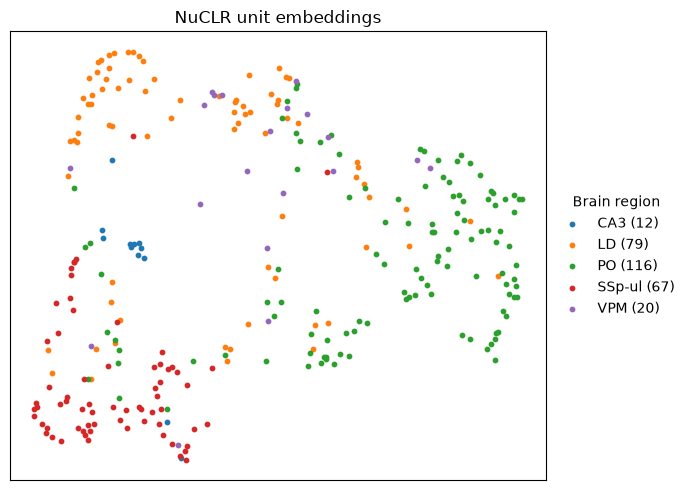

In [10]:
xy = umap.UMAP(random_state=0).fit_transform(x)

fig, ax = plt.subplots(figsize=(7, 5))
for r in np.unique(y):
    ax.scatter(*xy[y == r].T, s=10, label=f"{r} ({(y == r).sum()})")
ax.set(xticks=[], yticks=[], title="NuCLR unit embeddings")
ax.legend(title="Brain region", frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
plt.show()

The model only sees spikes, yet units from the same region end up close to each other, including neighbouring thalamic nuclei (LD, PO and VPM).

Try another checkpoint by changing `SEED`, or another region level such as `region_cosmos`.